MusicType – Eksperimen Klasifikasi Instrumen (IRMAS + MFCC)

Alur: membaca dataset lokal → memilih 11 kelas → ekstraksi 40 fitur MFCC → membandingkan 5 algoritma dengan 5-fold cross validation → evaluasi → menyimpan model terbaik.

535250075 William Richie Heriyanto

535250083 Sheireen Sadeli

535250098 Claudia Linetta Widjaja


In [9]:
# 1. Import library
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from joblib import Parallel, delayed
from features import file_features


In [10]:
import re
# 2. Membaca data dari folder dataset lokal

# Sesuaikan ROOT jika nama/lokasi folder dataset di komputer berbeda.
ROOT = Path("IRMAS-TrainingData")

CLASSES = {
    "cel": "Cello",
    "cla": "Clarinet",
    "flu": "Flute",
    "gac": "Gitar akustik",
    "gel": "Gitar elektrik",
    "org": "Organ",
    "pia": "Piano",
    "sax": "Saxophone",
    "tru": "Trumpet",
    "vio": "Biola",
    "voi": "Vokal"
}

rng = np.random.RandomState(42)
rows = []

for kode, nama in CLASSES.items():
    folder = ROOT / kode

    if not folder.is_dir():
        print(f"Folder kelas tidak ditemukan: {folder}")
        continue

    files = sorted(folder.glob("*.wav"))
    if len(files) == 0:
        print(f"Tidak ada file WAV di: {folder}")
        continue

    for file in files:
        rows.append((str(file), kode))

df_files = pd.DataFrame(rows, columns=["path", "label"])

# Grup = nama file tanpa akhiran "__<nomor potongan>". Klip 3 detik dari
# rekaman sumber yang sama (mis. "...0058__1.wav", "...0058__2.wav")
# mendapat grup yang sama, sehingga tidak terpecah ke train dan test.
df_files["group"] = df_files["path"].map(
    lambda p: re.sub(r"__\d+$", "", Path(p).stem)
)

if df_files.empty:
    raise FileNotFoundError(
        f"Data tidak ditemukan. Pastikan ROOT mengarah ke folder "
        f"IRMAS-TrainingData yang berisi subfolder pia, gac, vio, sax, flu, dan voi."
    )

print("Jumlah data:", len(df_files))
print("\nJumlah data per kelas:")
print(df_files["label"].value_counts().sort_index())

# Periksa beberapa nama file untuk memahami pola ID rekaman.
print("\nContoh path:")
print(df_files["path"].head())

print("\nJumlah klip:", len(df_files), "| jumlah grup (rekaman sumber):", df_files["group"].nunique())
print(df_files.groupby("group").size().describe().round(2))
print(df_files[["path", "group"]].head(6).to_string())


Jumlah data: 6705

Jumlah data per kelas:
label
cel    388
cla    505
flu    451
gac    637
gel    760
org    682
pia    721
sax    626
tru    577
vio    580
voi    778
Name: count, dtype: int64

Contoh path:
0    IRMAS-TrainingData\cel\008__[cel][nod][cla]005...
1    IRMAS-TrainingData\cel\008__[cel][nod][cla]005...
2    IRMAS-TrainingData\cel\008__[cel][nod][cla]005...
3    IRMAS-TrainingData\cel\012__[cel][nod][cla]004...
4    IRMAS-TrainingData\cel\012__[cel][nod][cla]004...
Name: path, dtype: str

Jumlah klip: 6705 | jumlah grup (rekaman sumber): 2273
count    2273.00
mean        2.95
std         0.24
min         1.00
25%         3.00
50%         3.00
75%         3.00
max         3.00
dtype: float64
                                                     path                     group
0  IRMAS-TrainingData\cel\008__[cel][nod][cla]0058__1.wav  008__[cel][nod][cla]0058
1  IRMAS-TrainingData\cel\008__[cel][nod][cla]0058__2.wav  008__[cel][nod][cla]0058
2  IRMAS-TrainingData\cel\008__[ce

In [ ]:
# 3. Ekstraksi fitur audio (166 fitur)

t0 = time.time()

feats = Parallel(n_jobs=-1)(
    delayed(file_features)(p)
    for p in df_files["path"]
)

t_ekstraksi = time.time() - t0

X = np.asarray(feats, dtype=float)
y = df_files["label"].astype(str).to_numpy()

# Nama kolom fitur
cols = []

for jenis in ["mfcc", "delta", "delta2"]:
    cols += [f"{jenis}{i}_mean" for i in range(20)]
    cols += [f"{jenis}{i}_std" for i in range(20)]

for jenis, jumlah in [
    ("chroma", 12),
    ("contrast", 7),
    ("centroid", 1),
    ("bandwidth", 1),
    ("rolloff", 1),
    ("zcr", 1)
]:
    cols += [f"{jenis}{i}_mean" for i in range(jumlah)]
    cols += [f"{jenis}{i}_std" for i in range(jumlah)]

assert X.shape[1] == len(cols), (
    f"Jumlah fitur tidak cocok: {X.shape[1]} vs {len(cols)}"
)

pd.DataFrame(X, columns=cols).assign(
    label=y
).to_csv("fitur_mfcc.csv", index=False)

print(f"Waktu ekstraksi: {t_ekstraksi:.1f} detik")
print("Ukuran matriks fitur:", X.shape)
print("Jumlah fitur:", X.shape[1])


Waktu ekstraksi: 112.0 detik
Ukuran matriks fitur: (6705, 166)
Jumlah fitur: 166


In [12]:
# 4. Eksperimen 5-fold cross validation (Stratified Group K-Fold, tanpa kebocoran antar-rekaman)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score
)

def buat_model(proba=False):
    # SVM eksperimen tidak memerlukan probabilitas.
    # Untuk model akhir, kalibrasi digunakan agar tersedia predict_proba().
    if proba:
        svm = CalibratedClassifierCV(
            estimator=make_pipeline(
                StandardScaler(),
                SVC(kernel="rbf", C=10)
            ),
            cv=5,
            ensemble=False
        )
        svm_model = svm
    else:
        svm_model = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=10)
        )

    return {
        "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB()),
        "SVM (RBF)": svm_model,
        "KNN (k=5)": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5)
        ),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, random_state=42, n_jobs=-1
        )
    }

groups = df_files["group"].to_numpy()
skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
hasil = []

for nama in buat_model():
    print("Menjalankan:", nama)
    for k, (tr, te) in enumerate(skf.split(X, y, groups), start=1):
        model = buat_model()[nama]

        t0 = time.time()
        model.fit(X[tr], y[tr])
        waktu_latih = time.time() - t0

        t0 = time.time()
        pred = model.predict(X[te])
        waktu_prediksi = time.time() - t0

        hasil.append({
            "Algoritma": nama,
            "Fold": k,
            "Precision": precision_score(
                y[te], pred, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y[te], pred, average="macro", zero_division=0
            ),
            "F1_macro": f1_score(
                y[te], pred, average="macro", zero_division=0
            ),
            "Akurasi": accuracy_score(y[te], pred),
            "Waktu_latih": waktu_latih,
            "Waktu_prediksi": waktu_prediksi
        })

df_fold = pd.DataFrame(hasil)
df_fold.to_csv("results_per_fold.csv", index=False)
df_fold.round(4)


Menjalankan: Naive Bayes


Menjalankan: SVM (RBF)
Menjalankan: KNN (k=5)
Menjalankan: Decision Tree
Menjalankan: Random Forest


,Algoritma,Fold,Precision,Recall,F1_macro,Akurasi,Waktu_latih,Waktu_prediksi
0,Naive Bayes,1,0.3885,0.3747,0.3546,0.3766,0.0690,0.0725
1,Naive Bayes,2,0.3798,0.3607,0.3342,0.3547,0.1357,0.1288
2,Naive Bayes,3,0.3988,0.3823,0.3625,0.3781,0.1559,0.1734
3,Naive Bayes,4,0.3945,0.3764,0.3482,0.3706,0.1675,0.0927
4,Naive Bayes,5,0.3900,0.3592,0.3444,0.3604,0.1220,0.0593
5,SVM (RBF),1,0.5860,0.5805,0.5819,0.5928,12.6152,4.9189
6,SVM (RBF),2,0.5363,0.5371,0.5353,0.5484,9.5479,4.6162
7,SVM (RBF),3,0.5679,0.5642,0.5631,0.5735,13.4305,4.9018
8,SVM (RBF),4,0.5879,0.5871,0.5864,0.5966,3.8947,1.3397
9,SVM (RBF),5,0.5709,0.5653,0.5662,0.5806,4.9232,1.5538


In [13]:
# 5. Ringkasan hasil 5-fold cross validation
for nama, grup in df_fold.groupby("Algoritma", sort=False):
    print("\n==", nama, "==")
    print(grup.drop(columns="Algoritma").set_index("Fold").round(4))
    print(
        "Rata-rata:",
        grup.drop(columns=["Algoritma", "Fold"]).mean().round(4).to_dict()
    )

ringkas = (
    df_fold.drop(columns="Fold")
    .groupby("Algoritma", sort=False)
    .mean()
    .round(4)
)
ringkas["F1_std"] = (
    df_fold.groupby("Algoritma", sort=False)["F1_macro"].std().round(4)
)
ringkas.to_csv("results_summary.csv")

print("\nPeringkat berdasarkan F1 macro:")
display(ringkas.sort_values("F1_macro", ascending=False))



== Naive Bayes ==
      Precision  Recall  F1_macro  Akurasi  Waktu_latih  Waktu_prediksi
Fold                                                                   
1        0.3885  0.3747    0.3546   0.3766       0.0690          0.0725
2        0.3798  0.3607    0.3342   0.3547       0.1357          0.1288
3        0.3988  0.3823    0.3625   0.3781       0.1559          0.1734
4        0.3945  0.3764    0.3482   0.3706       0.1675          0.0927
5        0.3900  0.3592    0.3444   0.3604       0.1220          0.0593
Rata-rata: {'Precision': 0.3903, 'Recall': 0.3706, 'F1_macro': 0.3488, 'Akurasi': 0.3681, 'Waktu_latih': 0.13, 'Waktu_prediksi': 0.1054}

== SVM (RBF) ==
      Precision  Recall  F1_macro  Akurasi  Waktu_latih  Waktu_prediksi
Fold                                                                   
1        0.5860  0.5805    0.5819   0.5928      12.6152          4.9189
2        0.5363  0.5371    0.5353   0.5484       9.5479          4.6162
3        0.5679  0.5642    0.5631  

,Precision,Recall,F1_macro,Akurasi,Waktu_latih,Waktu_prediksi,F1_std
Algoritma,,,,,,,
SVM (RBF),0.5698,0.5668,0.5666,0.5784,8.8823,3.4661,0.0201
Random Forest,0.5332,0.4993,0.4966,0.5175,4.2490,0.1598,0.0200
KNN (k=5),0.3800,0.3745,0.3632,0.3823,0.0367,0.0475,0.0101
Naive Bayes,0.3903,0.3706,0.3488,0.3681,0.1300,0.1054,0.0106
Decision Tree,0.3011,0.3016,0.3007,0.3065,1.2490,0.0022,0.0156


In [ ]:
# 5.1 Tuning hyperparameter SVM RBF (GridSearchCV)

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

param_grid = {
    "svc__C": [0.1, 1, 10, 100, 1000],
    "svc__gamma": ["scale", "auto", 0.001, 0.01, 0.1],
    "svc__class_weight": [None, "balanced"]
}

svm_pipeline = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="accuracy",
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid.fit(X, y, groups=groups)

print("Parameter terbaik:")
print(grid.best_params_)

print("\nAccuracy terbaik:")
print(round(grid.best_score_, 4))

print("\nF1 Macro:")
print(round(
    grid.cv_results_["mean_test_f1_macro"][grid.best_index_],
    4
))


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Parameter terbaik:
{'svc__C': 10, 'svc__class_weight': 'balanced', 'svc__gamma': 'scale'}

Accuracy terbaik:
0.5787

F1 Macro:
0.5668


Accuracy: 0.5787
F1 Macro: 0.5674

Classification Report:
              precision    recall  f1-score   support

         cel       0.58      0.58      0.58       388
         cla       0.53      0.53      0.53       505
         flu       0.44      0.41      0.42       451
         gac       0.62      0.69      0.65       637
         gel       0.50      0.59      0.54       760
         org       0.59      0.62      0.60       682
         pia       0.68      0.63      0.65       721
         sax       0.48      0.43      0.45       626
         tru       0.59      0.52      0.55       577
         vio       0.51      0.47      0.49       580
         voi       0.76      0.76      0.76       778

    accuracy                           0.58      6705
   macro avg       0.57      0.57      0.57      6705
weighted avg       0.58      0.58      0.58      6705



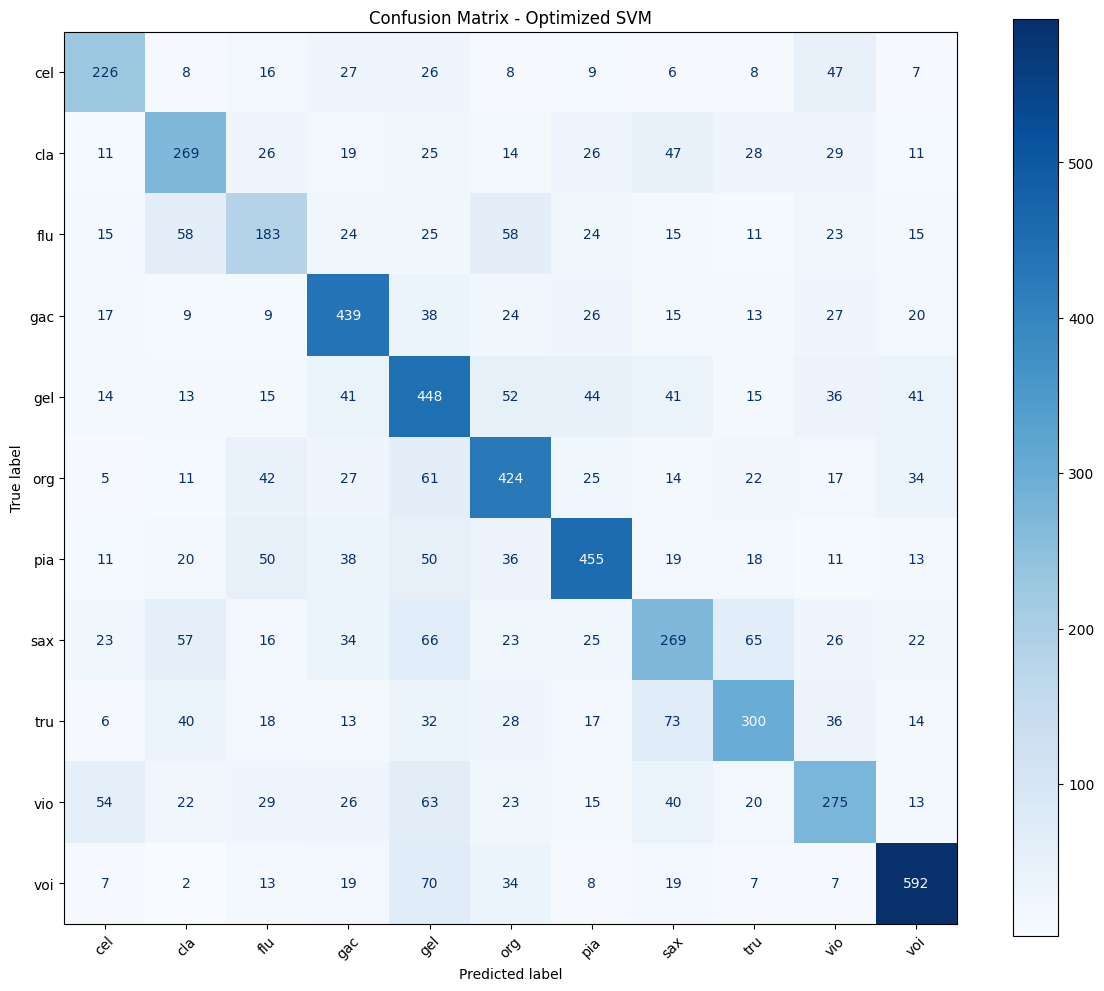

In [ ]:
# 5.2. Evaluasi SVM hasil tuning tahap ini

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Prediksi menggunakan StratifiedGroupKFold
y_pred = cross_val_predict(
    grid.best_estimator_,
    X,
    y,
    cv=skf,
    groups=groups,
    n_jobs=-1
)

# Evaluasi
print("Accuracy:", round(accuracy_score(y, y_pred), 4))
print("F1 Macro:", round(f1_score(y, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y, y_pred, zero_division=0))

# Confusion Matrix
labels = sorted(np.unique(y))

cm = confusion_matrix(y, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Confusion Matrix - Optimized SVM")
plt.tight_layout()
plt.show()


In [ ]:
# 5.3. Seleksi fitur dengan SelectKBest (ANOVA F-test)

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Pipeline: memilih fitur -> scaling -> SVM
svm_fs = make_pipeline(
    SelectKBest(score_func=f_classif),
    StandardScaler(),
    SVC(kernel="rbf")
)

# Kombinasi jumlah fitur dan parameter SVM
param_grid_fs = {
    "selectkbest__k": [60, 80, 100, 120, 140, "all"],
    "svc__C": [1, 10, 100],
    "svc__gamma": ["scale", 0.01],
    "svc__class_weight": [None, "balanced"]
}

grid_fs = GridSearchCV(
    estimator=svm_fs,
    param_grid=param_grid_fs,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="accuracy",
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_fs.fit(X, y, groups=groups)

print("Parameter terbaik:")
print(grid_fs.best_params_)

print("\nAccuracy terbaik:")
print(round(grid_fs.best_score_, 4))

print("\nF1 Macro:")
print(round(
    grid_fs.cv_results_["mean_test_f1_macro"][
        grid_fs.best_index_
    ],
    4
))


Fitting 5 folds for each of 72 candidates, totalling 360 fits
Parameter terbaik:
{'selectkbest__k': 120, 'svc__C': 100, 'svc__class_weight': None, 'svc__gamma': 'scale'}

Accuracy terbaik:
0.5945

F1 Macro:
0.5843


In [ ]:
# 5.4. Perbandingan kernel SVM (RBF, polynomial, linear) dengan k = 120

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipeline_kernel = make_pipeline(
    SelectKBest(score_func=f_classif, k=120),
    StandardScaler(),
    SVC()
)

param_grid_kernel = [
    {
        "svc__kernel": ["rbf"],
        "svc__C": [10, 100, 1000],
        "svc__gamma": ["scale", 0.001, 0.01],
        "svc__class_weight": [None, "balanced"]
    },
    {
        "svc__kernel": ["poly"],
        "svc__C": [1, 10, 100],
        "svc__degree": [2, 3],
        "svc__gamma": ["scale"],
        "svc__class_weight": [None, "balanced"]
    },
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10, 100],
        "svc__class_weight": [None, "balanced"]
    }
]

grid_kernel = GridSearchCV(
    estimator=pipeline_kernel,
    param_grid=param_grid_kernel,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="accuracy",
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_kernel.fit(X, y, groups=groups)

print("Kernel dan parameter terbaik:")
print(grid_kernel.best_params_)

print("\nAccuracy terbaik:")
print(round(grid_kernel.best_score_, 4))

print("\nF1 Macro:")
print(round(
    grid_kernel.cv_results_["mean_test_f1_macro"][
        grid_kernel.best_index_
    ],
    4
))


Fitting 5 folds for each of 38 candidates, totalling 190 fits
Kernel dan parameter terbaik:
{'svc__C': 100, 'svc__class_weight': None, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}

Accuracy terbaik:
0.5945

F1 Macro:
0.5843


In [ ]:
# 5.5. Skor ANOVA F setiap fitur

from sklearn.feature_selection import SelectKBest, f_classif
import pandas as pd

selector = SelectKBest(
    score_func=f_classif,
    k=120
)

selector.fit(X, y)

hasil_fitur = pd.DataFrame({
    "Fitur": cols,
    "Skor": selector.scores_,
    "Terpilih": selector.get_support()
})

hasil_fitur = hasil_fitur.sort_values(
    "Skor",
    ascending=False
)

print("10 Fitur Teratas:")
display(hasil_fitur.head(10))

print("\nJumlah fitur terpilih:")
print(selector.get_support().sum())

print("\nFitur yang tidak terpilih:")
display(
    hasil_fitur[hasil_fitur["Terpilih"] == False]
)


10 Fitur Teratas:


,Fitur,Skor,Terpilih
0,mfcc0_mean,267.643186,True
147,contrast3_mean,222.279262,True
160,bandwidth0_mean,201.671352,True
159,centroid0_std,188.995764,True
148,contrast4_mean,188.771192,True
162,rolloff0_mean,182.195638,True
158,centroid0_mean,179.955074,True
146,contrast2_mean,169.215535,True
163,rolloff0_std,167.867492,True
1,mfcc1_mean,157.358192,True



Jumlah fitur terpilih:
120

Fitur yang tidak terpilih:


,Fitur,Skor,Terpilih
142,chroma10_std,16.486054,False
18,mfcc18_mean,15.971526,False
133,chroma1_std,15.610412,False
140,chroma8_std,14.537476,False
136,chroma4_std,13.681245,False
84,delta24_mean,10.251648,False
19,mfcc19_mean,10.200410,False
141,chroma9_std,9.764879,False
139,chroma7_std,9.236219,False
82,delta22_mean,8.233324,False


In [ ]:
# 5.6. Penyempurnaan jumlah fitur (k = 105 sampai 135)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipeline_fitur = make_pipeline(
    SelectKBest(score_func=f_classif),
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=100,
        gamma="scale",
        class_weight=None
    )
)

param_grid_fitur = {
    "selectkbest__k": [105, 110, 115, 120, 125, 130, 135]
}

grid_fitur = GridSearchCV(
    estimator=pipeline_fitur,
    param_grid=param_grid_fitur,
    scoring={
        "accuracy": "accuracy",
        "f1_macro": "f1_macro"
    },
    refit="accuracy",
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_fitur.fit(X, y, groups=groups)

print("Jumlah fitur terbaik:")
print(grid_fitur.best_params_)

print("\nAccuracy terbaik:")
print(round(grid_fitur.best_score_, 4))

print("\nF1 Macro:")
print(round(
    grid_fitur.cv_results_["mean_test_f1_macro"][
        grid_fitur.best_index_
    ],
    4
))


Fitting 5 folds for each of 7 candidates, totalling 35 fits
Jumlah fitur terbaik:
{'selectkbest__k': 120}

Accuracy terbaik:
0.5945

F1 Macro:
0.5843


Model terbaik berdasarkan rata-rata F1 macro: SVM (RBF)


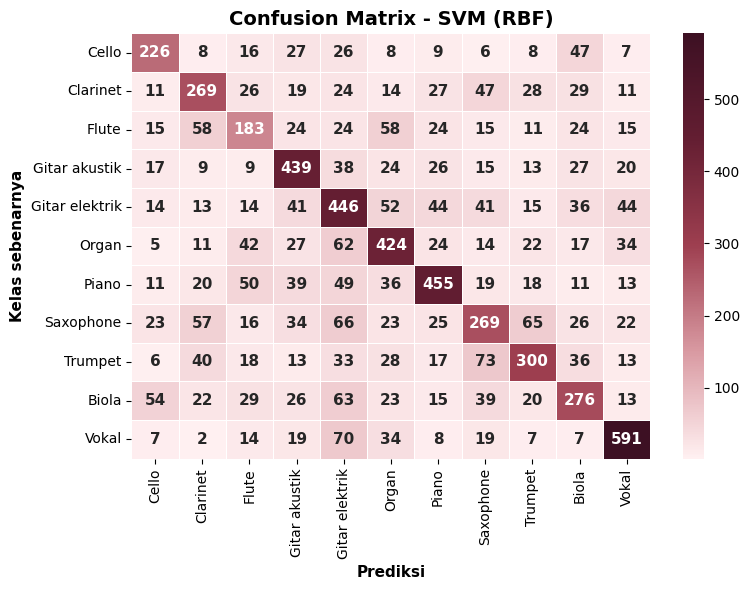

In [15]:
# 6. Confusion matrix model terbaik (prediksi out-of-fold)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
from matplotlib.colors import LinearSegmentedColormap

best_name = ringkas["F1_macro"].idxmax()
print("Model terbaik berdasarkan rata-rata F1 macro:", best_name)

model_terbaik = buat_model()[best_name]
pred_oof = cross_val_predict(
    model_terbaik, X, y, cv=skf, groups=groups, n_jobs=-1
)

labels = list(CLASSES.keys())
cm = confusion_matrix(y, pred_oof, labels=labels)

maroon_cmap = LinearSegmentedColormap.from_list(
    "maroon",
    ["#FFF0F1", "#D99AA2", "#9E3F50", "#641E32", "#3D1023"]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=maroon_cmap,
    xticklabels=list(CLASSES.values()),
    yticklabels=list(CLASSES.values()),
    linewidths=0.5,
    linecolor="white",
    annot_kws={"size": 11, "weight": "bold"}
)

plt.xlabel("Prediksi", fontsize=11, fontweight="bold")
plt.ylabel("Kelas sebenarnya", fontsize=11, fontweight="bold")
plt.title("Confusion Matrix - " + best_name, fontsize=14, fontweight="bold")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

In [16]:
# 7. Melatih ulang model terbaik dan menyimpan paket model
# Model akhir dilatih menggunakan seluruh data training.
# SVM dikalibrasi agar aplikasi dapat menampilkan probabilitas (predict_proba).
final = buat_model(proba=True)[best_name]
final.fit(X, y)

joblib_bundle = {
    "model": final,
    "best_name": best_name,
    "classes": list(final.classes_),
    "class_names": CLASSES,
    "segment_sec": 3.0
}

import joblib
joblib.dump(joblib_bundle, "model.joblib")

print("Model tersimpan: model.joblib")
print("Model terbaik:", best_name)
print("Urutan kelas:", joblib_bundle["classes"])
print("File hasil lain: results_summary.csv, results_per_fold.csv, confusion_matrix.png, fitur_mfcc.csv")


Model tersimpan: model.joblib
Model terbaik: SVM (RBF)
Urutan kelas: ['cel', 'cla', 'flu', 'gac', 'gel', 'org', 'pia', 'sax', 'tru', 'vio', 'voi']
File hasil lain: results_summary.csv, results_per_fold.csv, confusion_matrix.png, fitur_mfcc.csv


8. Catatan evaluasi

Cross validation pada notebook ini memakai `StratifiedGroupKFold`. Klip 3 detik yang berasal dari rekaman sumber yang sama berada di grup yang sama, sehingga tidak muncul di training dan testing sekaligus. Angka yang dihasilkan lebih rendah daripada `StratifiedKFold` biasa, tetapi lebih jujur terhadap kemampuan generalisasi.

Grup diambil dari nama file dengan membuang akhiran `__<nomor>`. Periksa output sel 2 (jumlah grup dan contoh `group`) untuk memastikan polanya benar.

Sel 10 mengevaluasi model akhir pada data test resmi IRMAS (polifonik, label lebih dari satu instrumen). Karena model single-label, metriknya adalah *hit rate* (prediksi termasuk salah satu instrumen sebenarnya), bukan akurasi biasa.

9. Evaluasi pada data test resmi IRMAS (opsional, perlu folder `IRMAS-TestingData`)


In [17]:
# 9. Evaluasi model akhir pada IRMAS-TestingData (audio polifonik, multi-label)
import joblib
import librosa
from features import SR, SEG_SEC, load_segments, seg_features

ROOT_TEST = Path("IRMAS-TestingData")
bundle = joblib.load("model.joblib")
mdl, kelas = bundle["model"], bundle["classes"]

if not ROOT_TEST.is_dir():
    print("Folder IRMAS-TestingData tidak ditemukan. Lewati sel ini.")
else:
    top1_hit, top3_hit, n = 0, 0, 0
    per_kelas = {k: [0, 0] for k in kelas}   # [hit top-1, jumlah]
    for wav in sorted(ROOT_TEST.rglob("*.wav")):
        txt = wav.with_suffix(".txt")
        if not txt.exists():
            continue
        benar = {l.strip() for l in txt.read_text().splitlines() if l.strip() in kelas}
        if not benar:
            continue
        _, segs = load_segments(str(wav), max_seconds=30)
        proba = mdl.predict_proba(np.asarray([seg_features(s) for s in segs])).mean(axis=0)
        urut = [kelas[i] for i in np.argsort(proba)[::-1]]
        n += 1
        top1_hit += urut[0] in benar
        top3_hit += bool(benar & set(urut[:3]))
        for b in benar:
            per_kelas[b][1] += 1
            per_kelas[b][0] += urut[0] == b

    print(f"Jumlah klip test: {n}")
    print(f"Hit rate top-1 (prediksi termasuk instrumen sebenarnya): {top1_hit / n:.3f}")
    print(f"Hit rate top-3 (salah satu dari 3 teratas benar)        : {top3_hit / n:.3f}")
    print("\nRecall top-1 per kelas:")
    for k, (h, t) in per_kelas.items():
        print(f"  {CLASSES[k]:15s} {h / max(t, 1):.2f}  (n={t})")


Folder IRMAS-TestingData tidak ditemukan. Lewati sel ini.
